In [1]:
print("Let's Start")

Let's Start


In [35]:
from sklearn.datasets import make_regression

x , y = make_regression(n_samples=500 , n_features=1 , noise=100 , bias=1, random_state=42)
x.shape , y.shape

((500, 1), (500,))

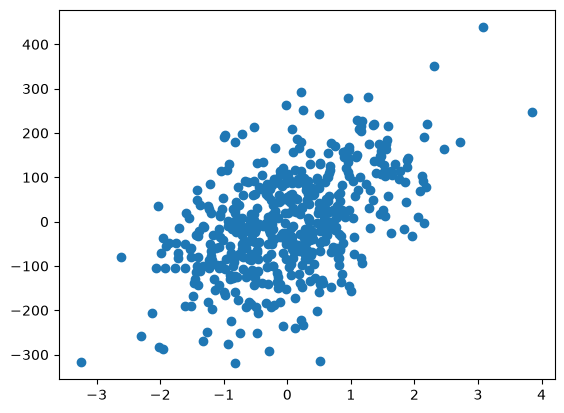

In [36]:
import matplotlib.pyplot as plt

plt.scatter(x ,y)

In [37]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x , y, test_size=0.2 , random_state=42)

Using Simple LinearRegression

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
lr = LinearRegression()
lr.fit(x_train , y_train)
lr_pred = lr.predict(x_test)
lr_score = r2_score(y_test , lr_pred)
print(lr_score)
print(lr.coef_ , lr.intercept_)
print("Training Score : " , lr.score(x_train , y_train))
print("Testing Score : " , lr.score(x_test , y_test))

0.29763518090048713
[56.19081927] -4.153056356556129
Training Score :  0.24045788853858263
Testing Score :  0.29763518090048713


Using Ridge of Sklearn

In [39]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=100)
ridge.fit(x_train , y_train)
ridge_pred = ridge.predict(x_test)
ridge_score = r2_score(y_test , ridge_pred)
print(ridge_score)
print(ridge.coef_ , ridge.intercept_)
print("Training Score : " , ridge.score(x_train , y_train))
print("Testing Score : " , ridge.score(x_test , y_test))

0.2675476293144915
[45.00319095] -4.095194450206276
Training Score :  0.2309258813641908
Testing Score :  0.2675476293144915


Using my own Ridge class

In [49]:
import numpy as np
class MyRidge:

    def __init__(self , alpha=1):
        self.alpha = alpha
        self.coef_ = None
        self.intercept_ = None

    def fit(self, x , y):
        y_bar = np.mean(y)
        x_bar = np.mean(x)
        num = 0
        den = 0
        for i in range(len(x)):
            num += np.sum(y[i] - y_bar) * np.sum(x[i] - x_bar)
            den += np.sum((x[i]- x_bar)*(x[i] - x_bar)) 
        self.coef_ = num/(den + self.alpha)
        self.intercept_ = y_bar - (self.coef_ * x_bar)
        print("Model Trained Successfully")

    def predict(self , x):
        return (self.coef_ * x) + self.intercept_

In [52]:
my = MyRidge(alpha=150)
my.fit(x_train , y_train)
my_pred = my.predict(x_test)
my_score = r2_score(y_test , my_pred)
print(my_score)
print(my.coef_ , my.intercept_)

Model Trained Successfully
0.25290219143527615
40.92872334880662 -4.074121488572067


[]

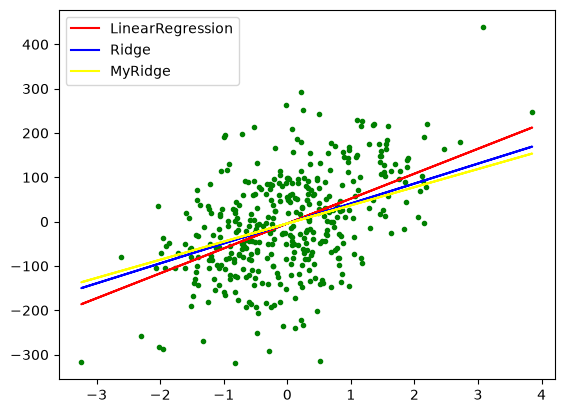

In [53]:
plt.plot(x_train , y_train , 'g.')
plt.plot(x_train , lr.predict(x_train) , color='red' ,label='LinearRegression')
plt.plot(x_train , ridge.predict(x_train) , color='blue' , label='Ridge')
plt.plot(x_train , my.predict(x_train) , color='yellow' , label='MyRidge')
plt.legend()
plt.plot()